## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Kevin Teng

**Date:** 10/14/2026

In [40]:
# Your Phase 1 solution to the problem goes here.

#Q1
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

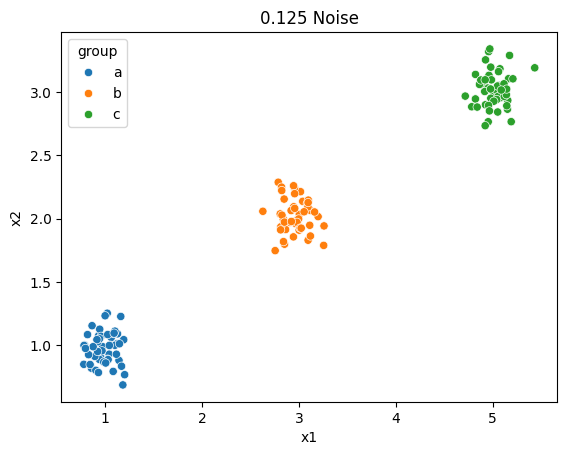

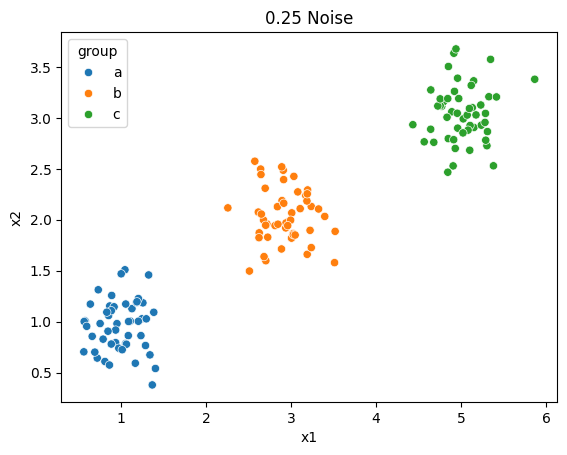

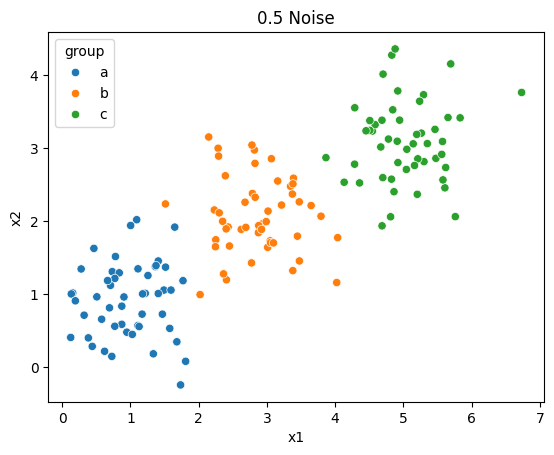

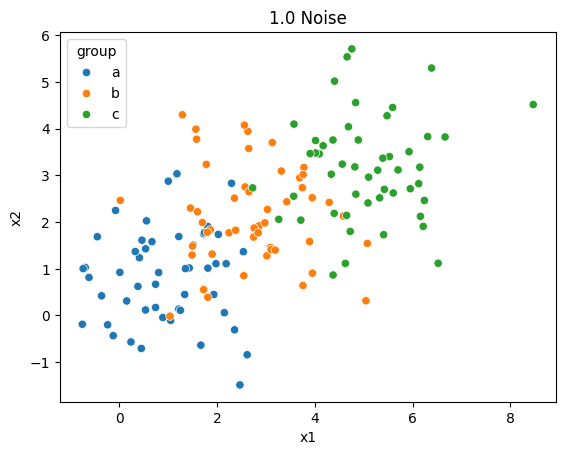

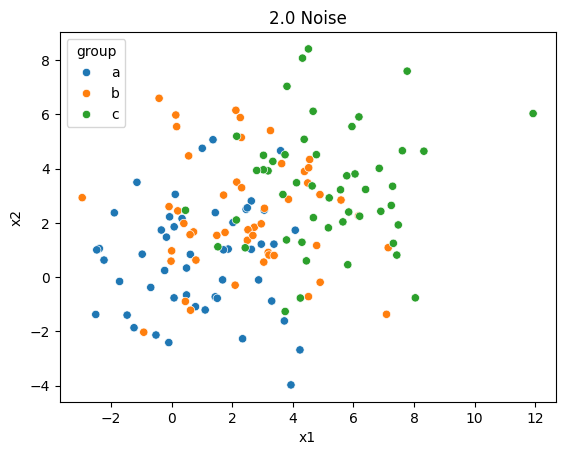

In [41]:
#Q2
import matplotlib.pyplot as plt
import seaborn as sns

sns.scatterplot(data=df0_125, x="x1", y="x2", hue="group")
plt.title("0.125 Noise")
plt.show()

sns.scatterplot(data=df0_25, x="x1", y="x2", hue="group")
plt.title("0.25 Noise")
plt.show()

sns.scatterplot(data=df0_5, x="x1", y="x2", hue="group")
plt.title("0.5 Noise")
plt.show()

sns.scatterplot(data=df1_0, x="x1", y="x2", hue="group")
plt.title("1.0 Noise")
plt.show()

sns.scatterplot(data=df2_0, x="x1", y="x2", hue="group")
plt.title("2.0 Noise")
plt.show()

Q1.2) As the noise gets larger, the groupings become less distinct. When noise = 0.125, we see three distinct groups for a, b, and c. As noise increases the groupings become less tight and start to overlap with other clusters. When noise = 2, we see that the clusters are significantly less distinct, with overlap between all three groups.

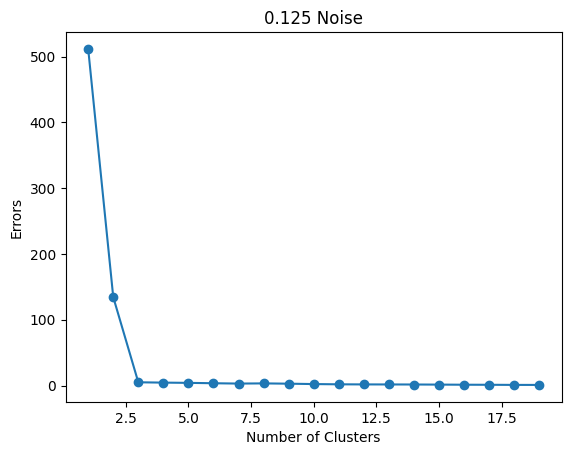

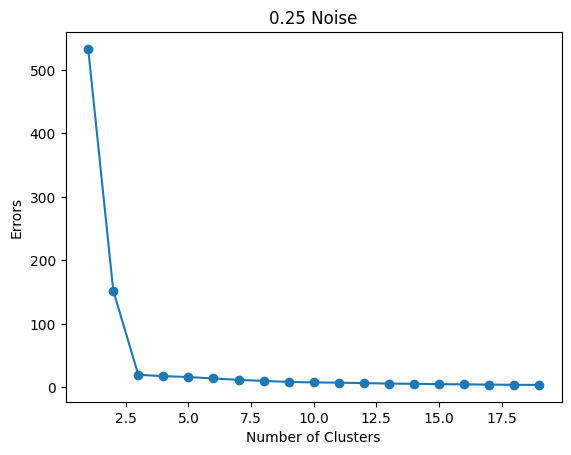

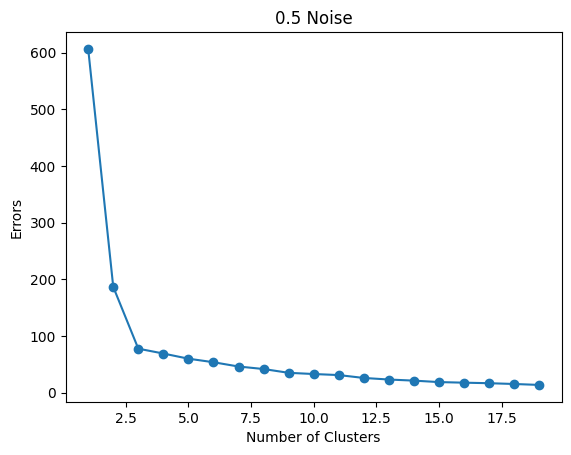

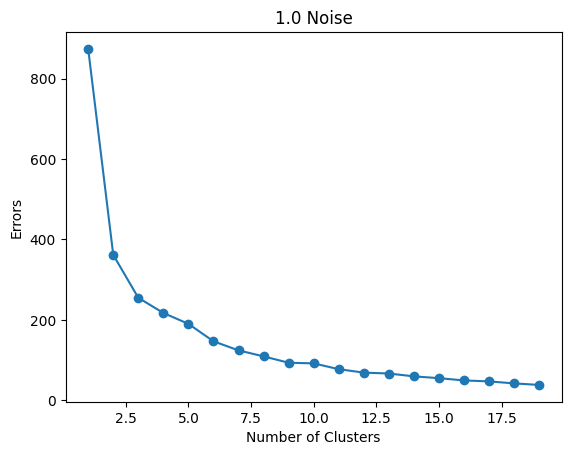

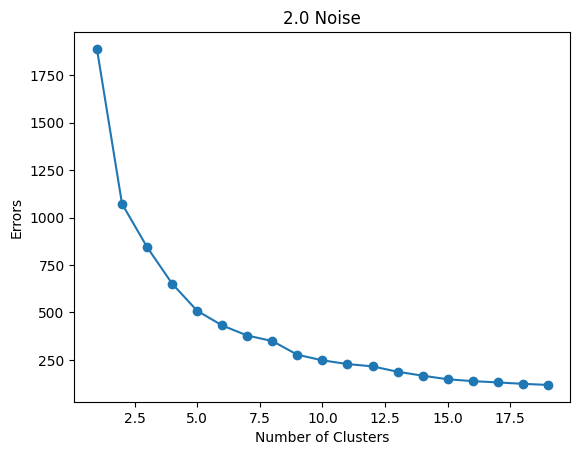

In [42]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

errors = []
for k in range(1, 20):
    model = KMeans(n_clusters=k, random_state=1)
    model.fit(df0_125[["x1", "x2"]])
    errors.append(model.inertia_)

plt.plot(range(1, 20), errors, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("Errors")
plt.title("0.125 Noise")
plt.show()

errors = []
for k in range(1, 20):
    model = KMeans(n_clusters=k, random_state=1)
    model.fit(df0_25[["x1", "x2"]])
    errors.append(model.inertia_)

plt.plot(range(1, 20), errors, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("Errors")
plt.title("0.25 Noise")
plt.show()

errors = []
for k in range(1, 20):
    model = KMeans(n_clusters=k, random_state=1)
    model.fit(df0_5[["x1", "x2"]])
    errors.append(model.inertia_)

plt.plot(range(1, 20), errors, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("Errors")
plt.title("0.5 Noise")
plt.show()

errors = []
for k in range(1, 20):
    model = KMeans(n_clusters=k, random_state=1)
    model.fit(df1_0[["x1", "x2"]])
    errors.append(model.inertia_)

plt.plot(range(1, 20), errors, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("Errors")
plt.title("1.0 Noise")
plt.show()

errors = []
for k in range(1, 20):
    model = KMeans(n_clusters=k, random_state=1)
    model.fit(df2_0[["x1", "x2"]])
    errors.append(model.inertia_)

plt.plot(range(1, 20), errors, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("Errors")
plt.title("2.0 Noise")
plt.show()



Q 1.3) As noises increases the plot starts to exhibits more of a gradual behavior rather than a sharp decline before leveling off. When the noise is lower, there is a sharp decrease in the error before starting to level out when the number of clusters, k, = 3. As noises increases, the error decreases gradually, making it harder to pinpoint exactly where the elbow is. Th error also grows larger, as shown by the large values on the y-axis, as noises increases.

Q 1.4) The elbow shows that adding more clusters reduces the error significantly in the beginning before the improvements start to plateau with marginal improvements. When the noise was lower, the error dropped sharply before leveling out at around k = 3, which suggests that 3 clusters are optimal, with more clusters providing minimal improvement. When noise increases, the elbow becomes less distinct since the data is more spread out with less distinct clusters, therefore making it harder to find the optimal number of clusters

In [43]:
#Q2.1
import pandas as pd
df = pd.read_csv("data/SIPRI Military Expenditure Database.csv")
print(df)
df_2020 = df[df["Year"] == 2020]
cleaned = df_2020.dropna()
#dropping index column redundant 
cleaned = cleaned.drop(columns=["index"])
cleaned


      index  Year      Country  Spending (2020 USD)  Percent of GDP  \
0         0  1988  Afghanistan                  NaN             NaN   
1         1  1989  Afghanistan                  NaN             NaN   
2         2  1990  Afghanistan                  NaN             NaN   
3         3  1991  Afghanistan                  NaN             NaN   
4         4  1992  Afghanistan                  NaN             NaN   
...     ...   ...          ...                  ...             ...   
5877   5877  2017     Zimbabwe           571.920778        0.003878   
5878   5878  2018     Zimbabwe           638.310913        0.003093   
5879   5879  2019     Zimbabwe           796.573534        0.005348   
5880   5880  2020     Zimbabwe             8.622460        0.000054   
5881   5881  2021     Zimbabwe            34.175047        0.000135   

      Percent of Government Spending  Spending per Capita  
0                                NaN                  NaN  
1                          

,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731
...,...,...,...,...,...,...
5506,2020,United Kingdom,60675.039625,0.022408,0.045629,893.778388
5540,2020,United States of America,778397.200000,0.037179,0.081976,2351.631858
5574,2020,Uruguay,1091.535360,0.021777,0.062082,314.201312
5846,2020,Zambia,212.142427,0.011542,0.034261,11.539514


Q2.1) The index column could also be dropped since it provides the same information row number information already provided by pandas.

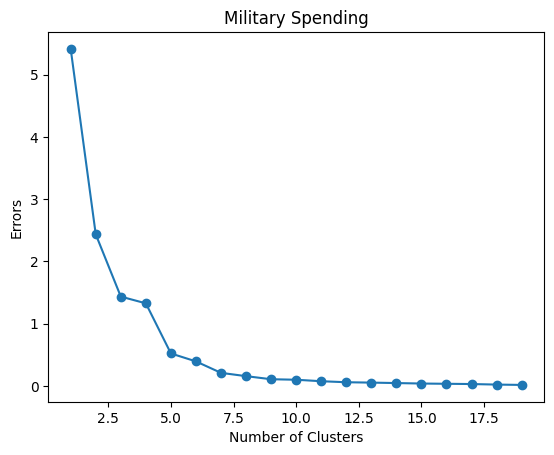

In [44]:
#Q2.2
from sklearn.cluster import KMeans

spending = cleaned[["Spending (2020 USD)", "Spending per Capita"]]
normalized = (spending - spending.min()) / (spending.max() - spending.min())

errors = []
for k in range(1, 20):
    model = KMeans(n_clusters=k, random_state=1)
    model.fit(normalized)
    errors.append(model.inertia_)

plt.plot(range(1, 20), errors, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("Errors")
plt.title("Military Spending")
plt.show()

model = KMeans(n_clusters=5, random_state=1)
model.fit(normalized)
cleaned["cluster"] = model.labels_

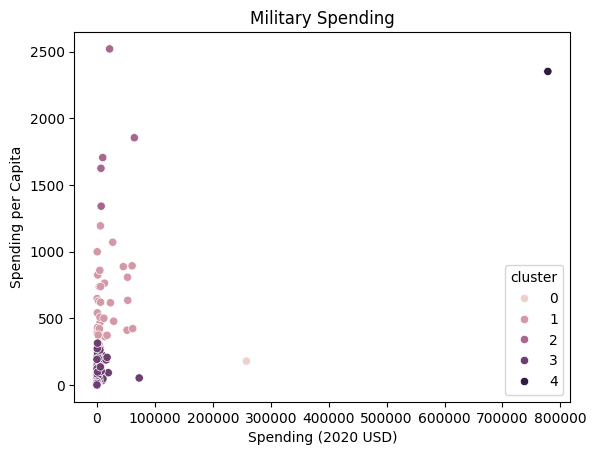

In [47]:
import seaborn as sns
sns.scatterplot(data=cleaned, x="Spending (2020 USD)", y="Spending per Capita", hue="cluster")
plt.title("Military Spending")
plt.show()

In [48]:
cleaned.groupby("cluster").describe()

Year                                                       \
         count    mean  std     min     25%     50%     75%     max   
cluster                                                               
0          1.0  2020.0  NaN  2020.0  2020.0  2020.0  2020.0  2020.0   
1         31.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
2          5.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
3        110.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
4          1.0  2020.0  NaN  2020.0  2020.0  2020.0  2020.0  2020.0   

        Spending (2020 USD)                 ...  \
                      count           mean  ...   
cluster                                     ...   
0                       1.0  257973.429834  ...   
1                      31.0   16723.337075  ...   
2                       5.0   22112.892714  ...   
3                     110.0    2558.146477  ...   
4                       1.0  778397.200000  ...   

        Percent of Government Spending           Spending per Capita  \
                                   75%       max               count   
cluster                                                                
0                             0.047517  0.047517                 1.0   
1                             0.050413  0.180654                31.0   
2                             0.116052  0.225050                 5.0   
3                             0.083820  0.303027               110.0   
4                             0.081976  0.081976                 1.0   

                                                                         \
                mean         std          min          25%          50%   
cluster                                                                   
0         179.232355         NaN   179.232355   179.232355   179.232355   
1         626.385718  229.072096   362.467076   422.432093   616.854430   
2        1809.346554  439.197280  1341.058851  1625.156250  1705.738706   
3          79.159917   83.339514     0.580129    14.848159    46.485917   
4        2351.631858         NaN  2351.631858  2351.631858  2351.631858   

                                   
                 75%          max  
cluster                            
0         179.232355   179.232355  
1         785.885227  1193.598730  
2        1854.380422  2520.398541  
3         121.424726   314.201312  
4        2351.631858  2351.631858  

[5 rows x 40 columns]

Q 2.2) What do you see? Where is the United States? Do you notice any patterns in the cluster membership?

There are five cluster with most countries (110) falling into cluster 3. Cluster 1 has the 2nd most countries at 31, and cluster 2 have 5 countries. THe remaining clusters, which are 0 and 4, only have 1 country each. Cluster 3 has a low mean spending and spending per capita. Cluster 1 contains countries with more moderate spending/spending per capita. Cluster 2 has a high spending per capita, comparable to the United States, but have lower overall spending due to country size. Cluster 4 is likely the United States since it has significantly higher spending than any other cluster. Cluster 1 could be a country like China since it is a large country, which boosts spending, but has relatively lower spending per capita.

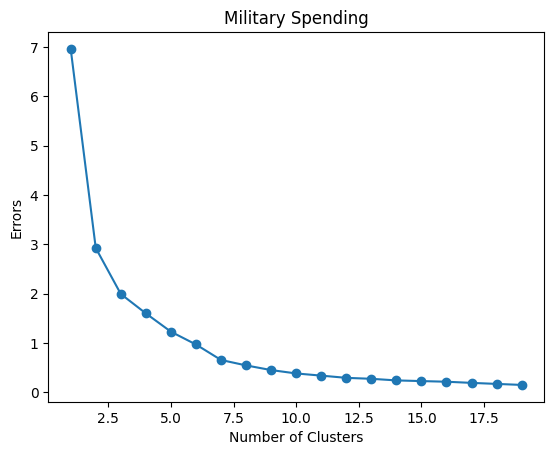

In [50]:
from sklearn.cluster import KMeans

spending = cleaned[["Percent of Government Spending", "Percent of GDP"]]
normalized = (spending - spending.min()) / (spending.max() - spending.min())

errors = []
for k in range(1, 20):
    model = KMeans(n_clusters=k, random_state=1)
    model.fit(normalized)
    errors.append(model.inertia_)

plt.plot(range(1, 20), errors, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("Errors")
plt.title("Military Spending")
plt.show()

model = KMeans(n_clusters=7, random_state=1)
model.fit(normalized)
cleaned["cluster"] = model.labels_

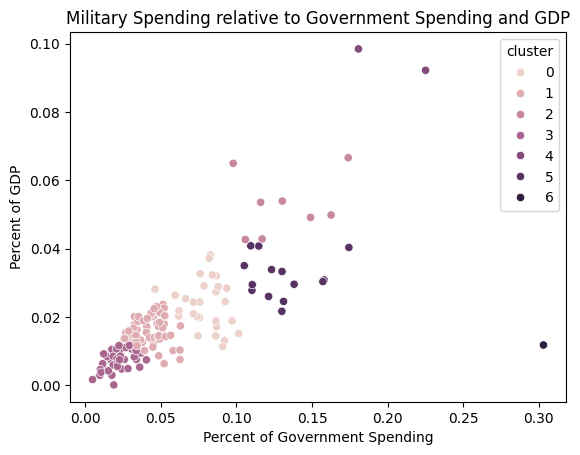

In [54]:
import seaborn as sns
sns.scatterplot(data=cleaned, x="Percent of Government Spending", y="Percent of GDP", hue="cluster")
plt.title("Military Spending relative to Government Spending and GDP")
plt.show()

In [53]:
cleaned.groupby("cluster").describe()

Year                                                       \
        count    mean  std     min     25%     50%     75%     max   
cluster                                                              
0        28.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
1        59.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
2         8.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
3        36.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
4         2.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
5        14.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
6         1.0  2020.0  NaN  2020.0  2020.0  2020.0  2020.0  2020.0   

        Spending (2020 USD)                ... Percent of Government Spending  \
                      count          mean  ...                            75%   
cluster                                    ...                                  
0                      28.0  32820.674392  ...                       0.087101   
1                      59.0  11040.803490  ...                       0.049284   
2                       8.0  13742.127964  ...                       0.152412   
3                      36.0   2622.890811  ...                       0.028511   
4                       2.0  35327.054356  ...                       0.213951   
5                      14.0   7188.981903  ...                       0.136403   
6                       1.0    707.418033  ...                       0.303027   

                  Spending per Capita                                        \
              max               count         mean         std          min   
cluster                                                                       
0        0.101501                28.0   199.961479  443.468431     5.674383   
1        0.062996                59.0   261.198202  309.482040     4.042961   
2        0.173924                 8.0   694.609603  887.512321   130.881211   
3        0.040459                36.0   129.939810  206.183226     0.580129   
4        0.225050                 2.0  1523.989576  467.243215  1193.598730   
5        0.174362                14.0   381.140973  519.185437    19.655822   
6        0.303027                 1.0    74.866974         NaN    74.866974   

                                                             
                 25%          50%          75%          max  
cluster                                                      
0          19.424522    84.673427   160.494986  2351.631858  
1          34.845855   104.137878   396.980508  1341.058851  
2         210.844490   221.050502   723.448894  2520.398541  
3           7.321429    31.699568   130.286729   738.263416  
4        1358.794153  1523.989576  1689.184999  1854.380422  
5          43.499696   120.920504   689.411500  1705.738706  
6          74.866974    74.866974    74.866974    74.866974  

[7 rows x 40 columns]

Q2.3) The clusters are more distributed in part 3, with 7 total clusters and 4 of those 7 clusters having 14 to 59 countries. This contrasts the distribution in part 2, which had more concentrated clusters having upwards of 110 countries. There are still outlier clusters in 4 and 6. However, these countries stand out because they allocate a significant proportion of economic resources to their military rather than having the most military spending like in part 2. Overall, this graph offers a different perspective by showing military spending with respect to a countries' economy and government budget rather than overall spending.

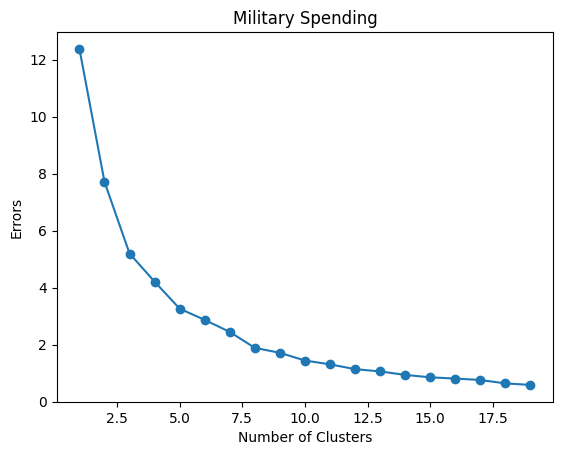

In [56]:
#Q2.4
from sklearn.cluster import KMeans

spending = cleaned[["Spending (2020 USD)", "Spending per Capita", "Percent of Government Spending", "Percent of GDP"]]
normalized = (spending - spending.min()) / (spending.max() - spending.min())

errors = []
for k in range(1, 20):
    model = KMeans(n_clusters=k, random_state=1)
    model.fit(normalized)
    errors.append(model.inertia_)

plt.plot(range(1, 20), errors, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("Errors")
plt.title("Military Spending")
plt.show()

model = KMeans(n_clusters=8, random_state=1)
model.fit(normalized)
cleaned["cluster"] = model.labels_

In [ ]:
import seaborn as sns
sns.scatterplot(data=cleaned, x="Percent of Government Spending", y="Percent of GDP", hue="cluster")
plt.title("Military Spending relative to Government Spending and GDP")
plt.show()

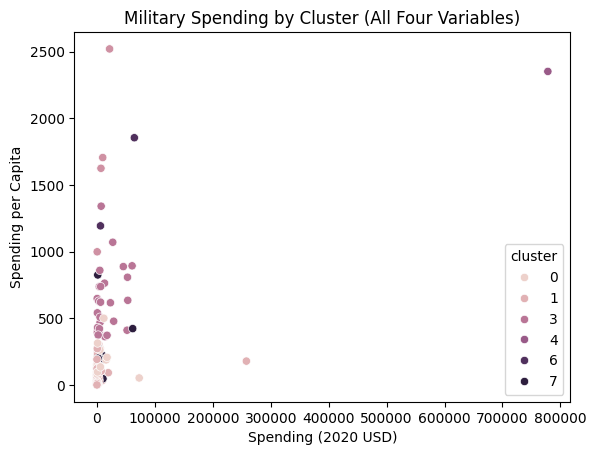

In [57]:
sns.scatterplot(
    data=cleaned,
    x="Spending (2020 USD)",
    y="Spending per Capita",
    hue="cluster"
)

plt.title("Military Spending by Cluster (All Four Variables)")
plt.show()

In [59]:
cleaned.groupby("cluster").describe()

Year                                                       \
        count    mean  std     min     25%     50%     75%     max   
cluster                                                              
0        31.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
1        68.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
2         4.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
3        27.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
4         1.0  2020.0  NaN  2020.0  2020.0  2020.0  2020.0  2020.0   
5         1.0  2020.0  NaN  2020.0  2020.0  2020.0  2020.0  2020.0   
6         2.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   
7        14.0  2020.0  0.0  2020.0  2020.0  2020.0  2020.0  2020.0   

        Spending (2020 USD)                 ...  \
                      count           mean  ...   
cluster                                     ...   
0                      31.0    5076.269832  ...   
1                      68.0    5109.722654  ...   
2                       4.0    9793.182941  ...   
3                      27.0   16448.891497  ...   
4                       1.0  778397.200000  ...   
5                       1.0     707.418033  ...   
6                       2.0   35327.054356  ...   
7                      14.0    7776.972928  ...   

        Percent of Government Spending           Spending per Capita  \
                                   75%       max               count   
cluster                                                                
0                             0.091502  0.131184                31.0   
1                             0.046138  0.062685                68.0   
2                             0.111880  0.116052                 4.0   
3                             0.045304  0.110270                27.0   
4                             0.081976  0.081976                 1.0   
5                             0.303027  0.303027                 1.0   
6                             0.213951  0.225050                 2.0   
7                             0.157730  0.174362                14.0   

                                                                         \
                mean         std          min          25%          50%   
cluster                                                                   
0         105.347262  115.972600     5.674383    19.048721    52.852792   
1          64.603961   74.104114     0.580129    11.508900    38.766382   
2        1712.564921  624.367729   998.966186  1468.608734  1665.447478   
3         622.872584  242.366106   362.467076   416.449490   616.854430   
4        2351.631858         NaN  2351.631858  2351.631858  2351.631858   
5          74.866974         NaN    74.866974    74.866974    74.866974   
6        1523.989576  467.243215  1193.598730  1358.794153  1523.989576   
7         207.286653  211.726203    19.655822    48.811293   194.633874   

                                   
                 75%          max  
cluster                            
0         142.682321   500.637259  
1          81.034731   303.716973  
2        1909.403664  2520.398541  
3         750.973480  1341.058851  
4        2351.631858  2351.631858  
5          74.866974    74.866974  
6        1689.184999  1854.380422  
7         221.221443   825.374403  

[8 rows x 40 columns]

Q 2.4) Part 4 has 8 distinct clusters, which exhibits patterns from both part 2 and 3. Part 4 has the United States grouped into its own cluster (4), due to its high military spending similar to part 2. However, the clusters are generally distributed more evenly with the largest cluster having 68 countries compared to the 110 countries in part 2. Part 4 also shows patterns from part 3 where clusters form due to high military spending relative to GDP/Government Spending. This is particularly evident in cluster 5, which has only one country, where the percent of military spending sits at 30.3% of government spending. Overall, using all four variables provides a more comprehensive look at the data, by considering total military spend and military spend relative to a countries economy/budget.

Q 2.5) Yes, the K-means clustering was useful in finding military spending patterns between countries. When clustering by total military spend, it revealed that most countries have relatively low military spend, except for the United States and one other country, which is likely China. The United States, in particular, had significantly more spending than all other countries and solely occupies the upper right quadrant of the scatter plot. In addition, clustering by percentage of GDP/government spending also showed how countries allocated their resources relative to their economic power. Overall, k-means was useful in clustering countries with similar spending patterns in a multi-faceted way by considering both total spend or proportional spend.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]